First 5 rows of the dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

Dataset shape:
(150, 5)

Target classes:
['setosa' 'versicolor' 'virginica']

Training data size: (120, 4)
Testing data size: (30, 4)

----------------------------------------
DECISION TREE CLASSIFIER
----------------------------------------
Accuracy: 100.0 %

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


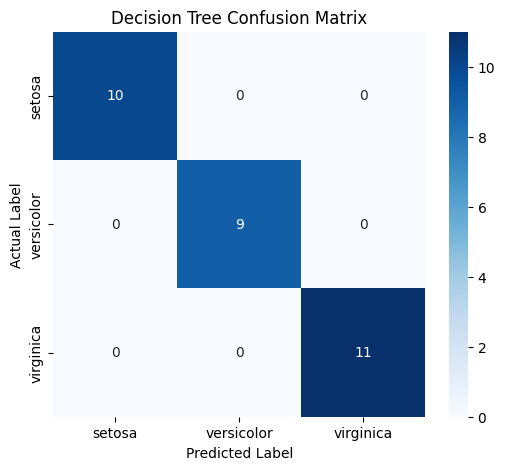


----------------------------------------
RANDOM FOREST CLASSIFIER
----------------------------------------
Accuracy: 100.0 %

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


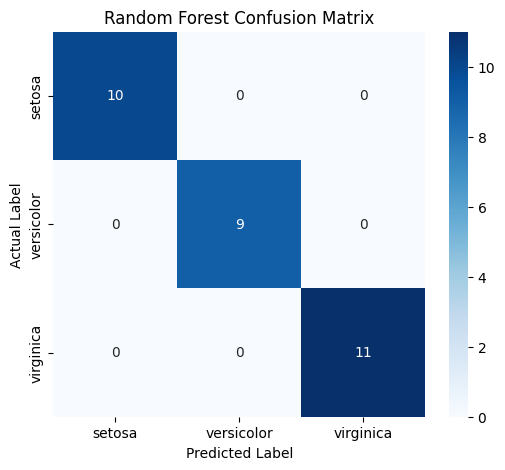


----------------------------------------
SUPPORT VECTOR MACHINE
----------------------------------------
Accuracy: 100.0 %

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


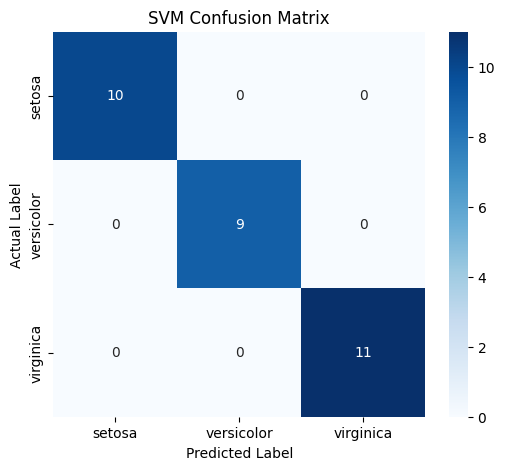


MODEL COMPARISON
           Model  Accuracy (%)
0  Decision Tree         100.0
1  Random Forest         100.0
2            SVM         100.0

RANDOM FOREST FEATURE IMPORTANCE
sepal length (cm) : 0.10809762464246378
sepal width (cm) : 0.030386812473242528
petal length (cm) : 0.43999397414456937
petal width (cm) : 0.4215215887397244


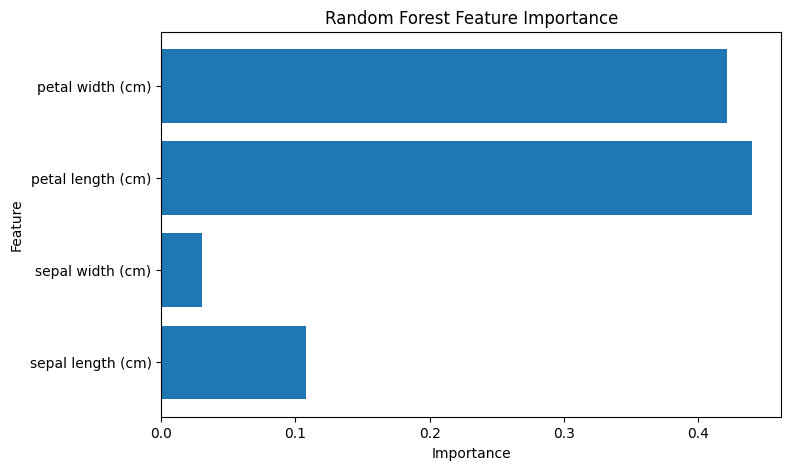

In [4]:
# Date: 16/09/2026
# ---------------------------------------------------------
# Classification using Decision Tree, Random Forest and SVM
# Dataset: Iris Dataset
# ---------------------------------------------------------

# 1. Import required libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, confusion_matrix


# ---------------------------------------------------------
# 2. Load the Iris dataset
# ---------------------------------------------------------

iris = load_iris()

# Create a DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df['target'] = iris.target

print("First 5 rows of the dataset:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nTarget classes:")
print(iris.target_names)


# ---------------------------------------------------------
# 3. Separate features and target
# ---------------------------------------------------------

X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values


# ---------------------------------------------------------
# 4. Split dataset into training and testing sets
# ---------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining data size:", X_train.shape)
print("Testing data size:", X_test.shape)


# ---------------------------------------------------------
# 5. Feature Scaling
# ---------------------------------------------------------

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# =========================================================
# 6. DECISION TREE CLASSIFIER
# =========================================================

dt_classifier = DecisionTreeClassifier(
    random_state=42
)

# Train the model
dt_classifier.fit(X_train, y_train)

# Make predictions
dt_pred = dt_classifier.predict(X_test)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, dt_pred)

print("\n----------------------------------------")
print("DECISION TREE CLASSIFIER")
print("----------------------------------------")

print("Accuracy:",
      dt_accuracy * 100, "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))


# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_test, dt_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


# =========================================================
# 7. RANDOM FOREST CLASSIFIER
# =========================================================

rf_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_classifier.fit(X_train, y_train)

# Make predictions
rf_pred = rf_classifier.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, rf_pred)

print("\n----------------------------------------")
print("RANDOM FOREST CLASSIFIER")
print("----------------------------------------")

print("Accuracy:",
      rf_accuracy * 100, "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))


# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_test, rf_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


# =========================================================
# 8. SUPPORT VECTOR MACHINE (SVM)
# =========================================================

svm_classifier = SVC(
    kernel='rbf'
)

# Train the model
svm_classifier.fit(X_train, y_train)

# Make predictions
svm_pred = svm_classifier.predict(X_test)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, svm_pred)

print("\n----------------------------------------")
print("SUPPORT VECTOR MACHINE")
print("----------------------------------------")

print("Accuracy:",
      svm_accuracy * 100, "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_pred))


# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_test, svm_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


# =========================================================
# 9. COMPARE ALL THREE MODELS
# =========================================================

results = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Random Forest',
        'SVM'
    ],
    'Accuracy (%)': [
        dt_accuracy * 100,
        rf_accuracy * 100,
        svm_accuracy * 100
    ]
})

print("\n========================================")
print("MODEL COMPARISON")
print("========================================")

print(results)


# =========================================================
# 10. RANDOM FOREST FEATURE IMPORTANCE
# =========================================================

feature_importances = rf_classifier.feature_importances_

print("\n========================================")
print("RANDOM FOREST FEATURE IMPORTANCE")
print("========================================")

for feature, importance in zip(
    iris.feature_names,
    feature_importances
):
    print(feature, ":", importance)


# Plot feature importance
plt.figure(figsize=(8, 5))

plt.barh(
    iris.feature_names,
    feature_importances
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.show()

First 5 rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  HouseValue  
0    -122.23       4.526  
1    -122.22       3.585  
2    -122.24       3.521  
3    -122.25       3.413  
4    -122.25       3.422  

Dataset shape:
(20640, 9)

Class distribution:
PriceClass
0    6884
1    6876
2    6880
Name: count, dtype: int64

0 = Low
1 = Medium
2 = High

Training data: (16512, 8)
Testing data: (4128, 8)

DECISION TREE CLASSIFIER
Accuracy: 73.08624031007753 %

Classification Report:
              precision    recall  f1-score   support

         Low       0.80      0.79    

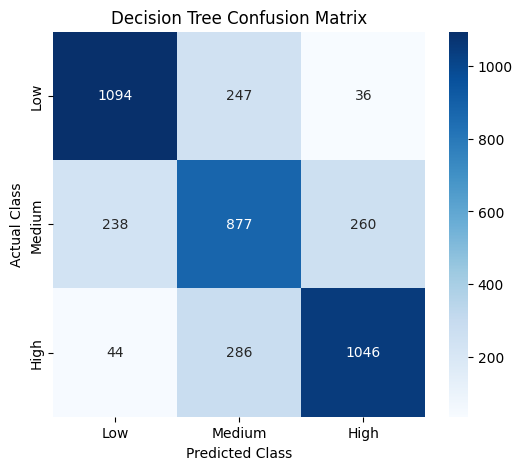


RANDOM FOREST CLASSIFIER
Accuracy: 80.78972868217055 %

Classification Report:
              precision    recall  f1-score   support

         Low       0.85      0.87      0.86      1377
      Medium       0.72      0.74      0.73      1375
        High       0.86      0.82      0.84      1376

    accuracy                           0.81      4128
   macro avg       0.81      0.81      0.81      4128
weighted avg       0.81      0.81      0.81      4128

Confusion Matrix:
[[1193  172   12]
 [ 184 1017  174]
 [  29  222 1125]]


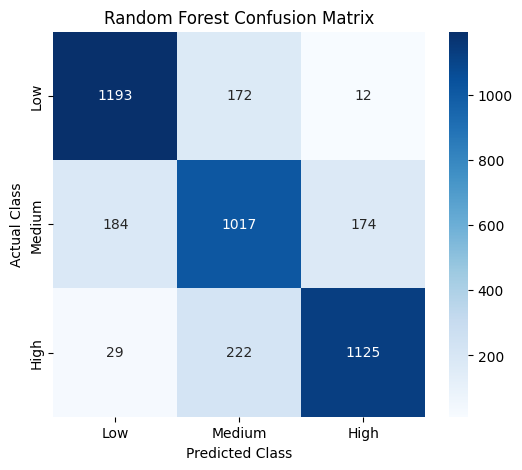


SUPPORT VECTOR CLASSIFIER
Accuracy: 74.8062015503876 %

Classification Report:
              precision    recall  f1-score   support

         Low       0.82      0.79      0.81      1377
      Medium       0.63      0.68      0.65      1375
        High       0.81      0.77      0.79      1376

    accuracy                           0.75      4128
   macro avg       0.75      0.75      0.75      4128
weighted avg       0.75      0.75      0.75      4128

Confusion Matrix:
[[1091  268   18]
 [ 208  936  231]
 [  33  282 1061]]


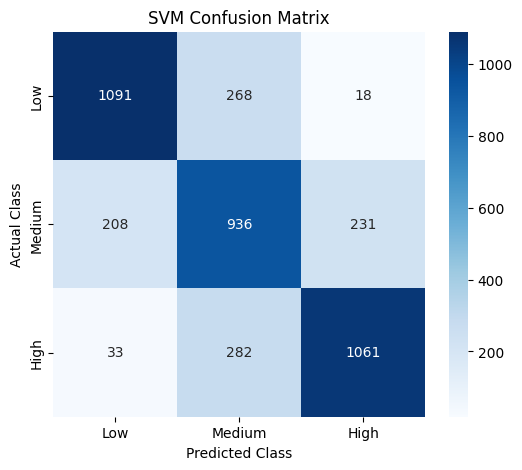


MODEL COMPARISON
           Model  Accuracy (%)
0  Decision Tree     73.086240
1  Random Forest     80.789729
2            SVM     74.806202

RANDOM FOREST FEATURE IMPORTANCE
      Feature  Importance
0      MedInc    0.242113
7   Longitude    0.170427
6    Latitude    0.159294
5    AveOccup    0.113955
2    AveRooms    0.112656
3   AveBedrms    0.069759
1    HouseAge    0.066392
4  Population    0.065404


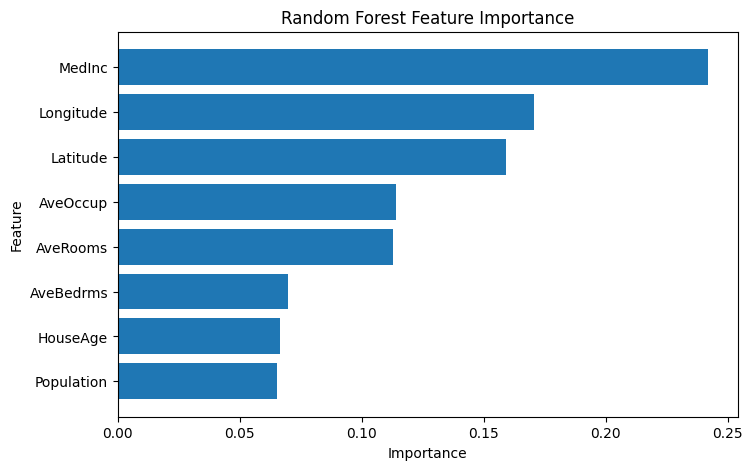

In [5]:
# ---------------------------------------------------------
# CLASSIFICATION USING HOUSING DATASET
# Algorithms:
# 1. Decision Tree Classifier
# 2. Random Forest Classifier
# 3. Support Vector Classifier (SVC)
#
# Dataset: California Housing Dataset
# ---------------------------------------------------------

# 1. Import required libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


# ---------------------------------------------------------
# 2. Load the Housing Dataset
# ---------------------------------------------------------

housing = fetch_california_housing()

# Create DataFrame
df = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

# Add original house value
df['HouseValue'] = housing.target

print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)


# ---------------------------------------------------------
# 3. Convert House Value into Classes
# ---------------------------------------------------------

# Divide house values into 3 categories:
# 0 = Low
# 1 = Medium
# 2 = High

df['PriceClass'] = pd.qcut(
    df['HouseValue'],
    q=3,
    labels=[0, 1, 2]
)

# Convert to integer
df['PriceClass'] = df['PriceClass'].astype(int)

print("\nClass distribution:")
print(df['PriceClass'].value_counts().sort_index())

print("\n0 = Low")
print("1 = Medium")
print("2 = High")


# ---------------------------------------------------------
# 4. Separate Features and Target
# ---------------------------------------------------------

X = df[housing.feature_names]

y = df['PriceClass']


# ---------------------------------------------------------
# 5. Split Dataset into Training and Testing Data
# ---------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)


# ---------------------------------------------------------
# 6. Feature Scaling
# ---------------------------------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# =========================================================
# 7. DECISION TREE CLASSIFIER
# =========================================================

dt_classifier = DecisionTreeClassifier(
    random_state=42
)

# Train
dt_classifier.fit(X_train, y_train)

# Predict
dt_pred = dt_classifier.predict(X_test)

# Accuracy
dt_accuracy = accuracy_score(y_test, dt_pred)

print("\n========================================")
print("DECISION TREE CLASSIFIER")
print("========================================")

print("Accuracy:",
      dt_accuracy * 100, "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        dt_pred,
        target_names=["Low", "Medium", "High"]
    )
)

print("Confusion Matrix:")
dt_cm = confusion_matrix(y_test, dt_pred)
print(dt_cm)


# Decision Tree Confusion Matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()


# =========================================================
# 8. RANDOM FOREST CLASSIFIER
# =========================================================

rf_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train
rf_classifier.fit(X_train, y_train)

# Predict
rf_pred = rf_classifier.predict(X_test)

# Accuracy
rf_accuracy = accuracy_score(y_test, rf_pred)

print("\n========================================")
print("RANDOM FOREST CLASSIFIER")
print("========================================")

print("Accuracy:",
      rf_accuracy * 100, "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=["Low", "Medium", "High"]
    )
)

print("Confusion Matrix:")
rf_cm = confusion_matrix(y_test, rf_pred)
print(rf_cm)


# Random Forest Confusion Matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()


# =========================================================
# 9. SUPPORT VECTOR CLASSIFIER
# =========================================================

svm_classifier = SVC(
    kernel='rbf'
)

# Train using scaled data
svm_classifier.fit(
    X_train_scaled,
    y_train
)

# Predict
svm_pred = svm_classifier.predict(
    X_test_scaled
)

# Accuracy
svm_accuracy = accuracy_score(
    y_test,
    svm_pred
)

print("\n========================================")
print("SUPPORT VECTOR CLASSIFIER")
print("========================================")

print("Accuracy:",
      svm_accuracy * 100, "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        svm_pred,
        target_names=["Low", "Medium", "High"]
    )
)

print("Confusion Matrix:")
svm_cm = confusion_matrix(
    y_test,
    svm_pred
)

print(svm_cm)


# SVM Confusion Matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()


# =========================================================
# 10. COMPARE ALL THREE MODELS
# =========================================================

results = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Random Forest',
        'SVM'
    ],

    'Accuracy (%)': [
        dt_accuracy * 100,
        rf_accuracy * 100,
        svm_accuracy * 100
    ]
})

print("\n========================================")
print("MODEL COMPARISON")
print("========================================")

print(results)


# =========================================================
# 11. RANDOM FOREST FEATURE IMPORTANCE
# =========================================================

feature_importance = rf_classifier.feature_importances_

importance_df = pd.DataFrame({
    'Feature': housing.feature_names,
    'Importance': feature_importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("\n========================================")
print("RANDOM FOREST FEATURE IMPORTANCE")
print("========================================")

print(importance_df)


# Plot feature importance
plt.figure(figsize=(8, 5))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance']
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.show()

First 5 rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  HouseValue  
0    -122.23       4.526  
1    -122.22       3.585  
2    -122.24       3.521  
3    -122.25       3.413  
4    -122.25       3.422  

Dataset Shape:
(20640, 9)

Class Distribution:
PriceClass
0    6884
1    6876
2    6880
Name: count, dtype: int64

Class Labels:
0 = Low
1 = Medium
2 = High

Training Data: (16512, 8)
Testing Data: (4128, 8)

STACKING CLASSIFIER
Base Model  : Random Forest Classifier
Meta Model  : Support Vector Classifier

Accuracy: 80.76550387596899 %

Classification Report:
   

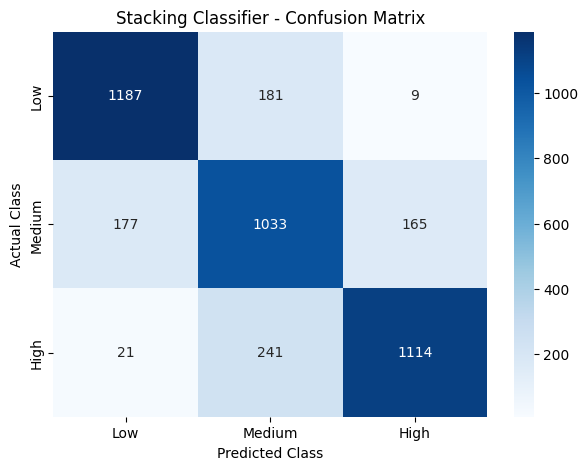

In [6]:
# ---------------------------------------------------------
# STACKING CLASSIFIER
# Base Model  : Random Forest Classifier
# Meta Model  : Support Vector Classifier (SVC)
# Dataset     : California Housing Dataset
# ---------------------------------------------------------

# 1. Import required libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


# ---------------------------------------------------------
# 2. Load California Housing Dataset
# ---------------------------------------------------------

housing = fetch_california_housing()

df = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

df['HouseValue'] = housing.target

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)


# ---------------------------------------------------------
# 3. Convert continuous house value into 3 classes
# ---------------------------------------------------------

# 0 = Low
# 1 = Medium
# 2 = High

df['PriceClass'] = pd.qcut(
    df['HouseValue'],
    q=3,
    labels=[0, 1, 2]
)

df['PriceClass'] = df['PriceClass'].astype(int)

print("\nClass Distribution:")
print(df['PriceClass'].value_counts().sort_index())

print("\nClass Labels:")
print("0 = Low")
print("1 = Medium")
print("2 = High")


# ---------------------------------------------------------
# 4. Separate Features and Target
# ---------------------------------------------------------

X = df[housing.feature_names]

y = df['PriceClass']


# ---------------------------------------------------------
# 5. Split dataset
# ---------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# ---------------------------------------------------------
# 6. Feature Scaling
# ---------------------------------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


# ---------------------------------------------------------
# 7. Define Base Model
# ---------------------------------------------------------

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)


# ---------------------------------------------------------
# 8. Define Meta Model
# ---------------------------------------------------------

svm = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)


# ---------------------------------------------------------
# 9. Create Stacking Classifier
# ---------------------------------------------------------

stacking_model = StackingClassifier(
    estimators=[
        ('random_forest', random_forest)
    ],
    final_estimator=svm,
    cv=5
)


# ---------------------------------------------------------
# 10. Train Stacking Model
# ---------------------------------------------------------

stacking_model.fit(
    X_train_scaled,
    y_train
)


# ---------------------------------------------------------
# 11. Make Predictions
# ---------------------------------------------------------

y_pred = stacking_model.predict(
    X_test_scaled
)


# ---------------------------------------------------------
# 12. Calculate Accuracy
# ---------------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\n========================================")
print("STACKING CLASSIFIER")
print("========================================")

print("Base Model  : Random Forest Classifier")
print("Meta Model  : Support Vector Classifier")

print("\nAccuracy:",
      accuracy * 100, "%")


# ---------------------------------------------------------
# 13. Classification Report
# ---------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Low",
            "Medium",
            "High"
        ]
    )
)


# ---------------------------------------------------------
# 14. Confusion Matrix
# ---------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)


# ---------------------------------------------------------
# 15. Plot Confusion Matrix
# ---------------------------------------------------------

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        "Low",
        "Medium",
        "High"
    ],
    yticklabels=[
        "Low",
        "Medium",
        "High"
    ]
)

plt.title(
    "Stacking Classifier - Confusion Matrix"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()